# 075 — caracterizacao escaloes

Caracterização socioeconómica/saúde dos escalões só nas 8.769 linhas de treino. Respostas especiais distintas. Sem CSV Kaggle.

**Estado: executado pelo runner; outputs guardados.**

Seleção dentro do treino de desenvolvimento (8.769 linhas), com os mesmos três folds. Validação fixa: 2.193 linhas, já observada anteriormente. Pré-processamento ajustado dentro de cada treino. Sem submissão automática.

075 resultado completo reutilizado após verificar o contexto.
Estado: procedimento concluído; resultados guardados com contexto verificado.
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração original (s): 1.2654402920015855
Notas: Só 8769 linhas de treino. Prevalências CD1 usam apenas respostas explícitas Sim/Não; restantes respostas são reportadas separadamente. Não inferir escalas clínicas nem converter Não aplicável em ausência de doença.
CSV Kaggle: None
Pontuação Kaggle: None


,age_class,variable,answer,n,proportion
162,0,MAINSTAT,"Aluno, estudante, ou em estágio curricular",164,0.987952
346,14,MAINSTAT,"Reformado, com reforma antecipada ou cessou a ...",474,0.911538
360,15,MAINSTAT,"Reformado, com reforma antecipada ou cessou a ...",358,0.901763
373,12,MAINSTAT,"Reformado, com reforma antecipada ou cessou a ...",715,0.893750
383,13,MAINSTAT,"Reformado, com reforma antecipada ou cessou a ...",582,0.884498
...,...,...,...,...,...
1903,6,HS2,Sem resposta,3,0.004367
1918,9,HS2,Sem resposta,3,0.003699
1931,3,HS2,Sem resposta,1,0.003311
1951,4,HS2,Sem resposta,1,0.002786


,age_class,variable,n,missing,mean,median,q25,q75
0,0,BM1,164,2,166.676829,166.000000,160.000000,172.250000
1,0,BM2,163,3,62.306748,60.000000,53.000000,70.000000
2,0,BMI,162,4,22.445041,21.506728,19.508258,24.198288
3,0,HH_ACT,166,0,1.542169,2.000000,1.000000,2.000000
4,0,HH_INACT,166,0,1.156627,1.000000,1.000000,2.000000
...,...,...,...,...,...,...,...,...
75,15,BM1,379,18,159.358839,160.000000,153.000000,165.000000
76,15,BM2,369,28,65.525745,65.000000,56.000000,74.000000
77,15,BMI,358,39,25.777036,25.711335,23.252309,28.305332
78,15,HH_ACT,397,0,0.128463,0.000000,0.000000,0.000000


,age_class,variable,yes,yes_no_answers,proportion_among_yes_no,other_or_special_answers
0,0,CD1A,20,166,0.120482,0
1,0,CD1B,6,166,0.036145,0
2,0,CD1C,0,166,0.000000,0
3,0,CD1D,0,165,0.000000,1
4,0,CD1E,0,166,0.000000,0
...,...,...,...,...,...,...
251,15,CD1L,3,393,0.007634,4
252,15,CD1M,117,395,0.296203,2
253,15,CD1N,54,390,0.138462,7
254,15,CD1O,60,396,0.151515,1


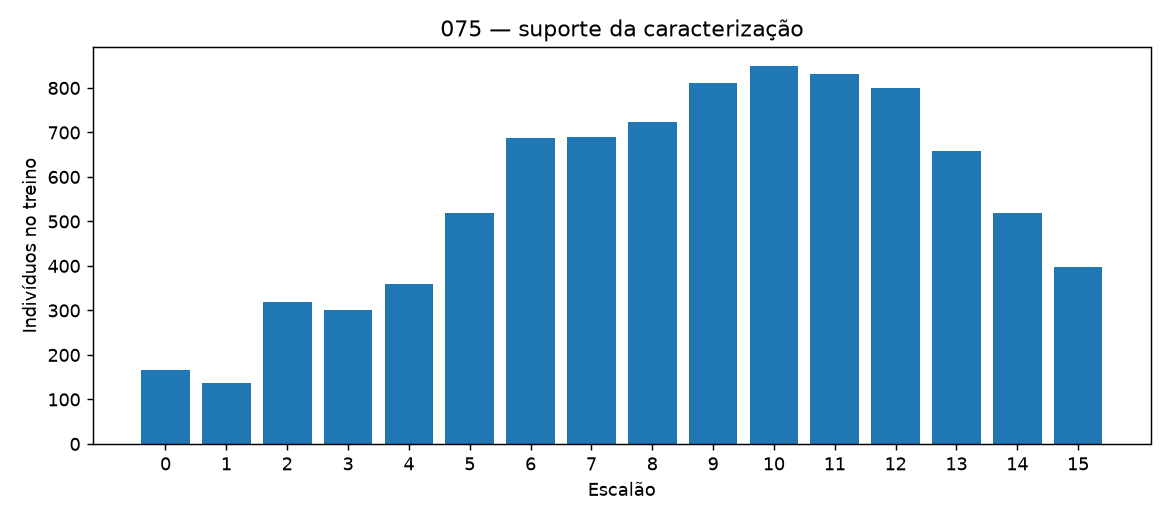

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p/'src/experiments_059_075.py').is_file())
sys.path.insert(0, str(root))
from src.experiments_059_075 import run_experiment
result = run_experiment('075')
print('Estado: procedimento concluído; resultados guardados com contexto verificado.')
print('Versões:', result['context']['base']['versions'])
print('Duração original (s):', result['seconds'])
print('Notas:', result.get('note', ''))
if result.get('candidates'):
    display(pd.DataFrame([{'configuração':r['label'],'Macro F1 CV':r['mean'],'DP':r['std'],'folds':r.get('folds',r.get('scores'))} for r in result['candidates']]))
if result.get('selected'):
    print('Selecionado:', result['selected']['label'])
    print('Configuração:', result['selected']['spec'])
if result.get('paired_cv'):
    print('Diferenças emparelhadas:', result['paired_cv'])
if result.get('fixed'):
    display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':groups[part]['macro_f1'],'accuracy':groups[part]['accuracy']} for name,groups in result['fixed'].items() for part in ['train','validation']]))
    for name, groups in result['fixed'].items():
        print('Escalões:', name)
        display(pd.DataFrame(groups['validation']['per_class']))
        print('Diagnósticos de ajuste:', groups.get('diagnostics'))
        print('MAE em códigos de escalão (não anos):', groups.get('mae_in_class_codes'))
        if 'log_loss' in groups: print('Log loss:',groups['log_loss'])
if result.get('metrics_oof'):
    print('Métricas OOF de desenvolvimento:', result['metrics_oof']['macro_f1'], result['metrics_oof']['accuracy'])
    display(pd.DataFrame(result['metrics_oof']['per_class']))
if 'selected_cases' in result:
    print('Perfis sinalizados:', result['flagged'], '/', result['total'])
    display(pd.DataFrame(result['selected_cases']))
    display(pd.DataFrame(result['by_class']))
if 'categorical_profiles' in result:
    table = pd.DataFrame(result['categorical_profiles'])
    display(table[table.variable.isin(['HATLEVEL','MAINSTAT','HHINCOME','HS1','HS2'])])
    display(pd.DataFrame(result['numeric_profiles']))
    display(pd.DataFrame(result['chronic_diseases']))
for file in sorted((root/'reports').glob('experiencia_075_*.png')):
    display(Image(filename=str(file)))
print('CSV Kaggle:', result.get('submission'))
print('Pontuação Kaggle:', result['kaggle_score'])


## Conclusões locais

- Análise concluída; consultar tabelas e gráficos. Não gera submissão Kaggle.

Só 8769 linhas de treino. Prevalências CD1 usam apenas respostas explícitas Sim/Não; restantes respostas são reportadas separadamente. Não inferir escalas clínicas nem converter Não aplicável em ausência de doença.

**Decisão:** preencher depois da revisão; não inferir melhoria pública de uma pequena diferença local.

## Registo manual

- Data:
- CSV submetido (se aplicável):
- Nota Kaggle:
- Conclusão:
- Melhorias a experimentar:

Esta célula e quaisquer notas pessoais não são substituídas pelo script.